# Check New `arbutus.cloud` Results of `nowcast-blue` Run

Compare results of a SalishSeaCast v202111 `nowcast-blue` (physics-only) run from the 2026 `arbutus.cloud`
to one from the pre-2026 `arbutus.cloud`.

The 2026 `arbutus.cloud` run uses builds from newer compilers and libraries (Ubuntu 24.04) and runs on fewer nodes.


In [1]:
import sys
from pathlib import Path

import arrow
import cmocean
import matplotlib.pyplot as plt
import xarray

Python and library versions:

In [2]:
import h5netcdf
import h5py
import matplotlib
import numpy
import pandas

print(f"Python {sys.version=}")
print(f"{numpy.__version__=}")
print(f"{xarray.__version__=}")
print(f"{pandas.__version__=}")
print(f"{h5netcdf.__version__=}")
print(f"{h5py.__version__=}")
print(f"{matplotlib.__version__=}")
print(f"{cmocean.__version__=}")
print(f"{arrow.__version__=}")

Python sys.version='3.14.6 | packaged by conda-forge | (main, Jul 24 2026, 16:09:24) [GCC 14.3.0]'
numpy.__version__='2.5.1'
xarray.__version__='2026.7.0'
pandas.__version__='3.0.5'
h5netcdf.__version__='1.8.1'
h5py.__version__='3.16.0'
matplotlib.__version__='3.11.1'
cmocean.__version__='v3.0.3'
arrow.__version__='1.4.0'


In [3]:
results_paths = {
  "baseline": Path("/results/SalishSea/nowcast-blue.202111/30jun26/"),
  "new arbutus": Path("/data/dlatorne/arbutus-2026/nowcast/30jun26/"),
}

In [4]:
drop_vars = {
  "nav_lat", "nav_lon",
  "bounds_nav_lat", "bounds_nav_lon",
  "time_centered", "time_centered_bounds", "time_counter_bounds",
  "deptht_bounds", "area",
}

## Salinity Fields Comparison

In [6]:
new_arbutus_ds = xarray.open_dataset(
    results_paths["new arbutus"] / "SalishSea_1h_20260630_20260630_grid_T.nc",
    drop_variables=drop_vars, engine="h5netcdf"
)

new_arbutus_ds

<xarray.Dataset> Size: 6GB
Dimensions:       (time_counter: 24, y: 898, x: 398, deptht: 40)
Coordinates:
  * time_counter  (time_counter) datetime64[ns] 192B 2026-06-30T00:30:00 ... ...
  * deptht        (deptht) float32 160B 0.5 1.5 2.5 3.5 ... 387.6 414.5 441.5
Dimensions without coordinates: y, x
Data variables:
    sossheig      (time_counter, y, x) float32 34MB ...
    votemper      (time_counter, deptht, y, x) float32 1GB ...
    vosaline      (time_counter, deptht, y, x) float32 1GB ...
    sigma_theta   (time_counter, deptht, y, x) float32 1GB ...
    e3t           (time_counter, deptht, y, x) float32 1GB ...
Attributes:
    name:         SalishSea_1h_20260630_20260630_grid_T
    description:  physics tracers and VVL layer thicknesses
    title:        physics tracers and VVL layer thicknesses
    Conventions:  CF-1.6
    timeStamp:    2026-Jul-20 18:26:08 GMT
    uuid:         12660b9d-2ff8-423e-be42-5268c11bcedc

In [8]:
baseline_ds = xarray.open_dataset(
    results_paths["baseline"] / "SalishSea_1h_20260630_20260630_grid_T.nc",
    drop_variables=drop_vars, engine="h5netcdf"
)

baseline_ds

<xarray.Dataset> Size: 6GB
Dimensions:       (time_counter: 24, y: 898, x: 398, deptht: 40)
Coordinates:
  * time_counter  (time_counter) datetime64[ns] 192B 2026-06-30T00:30:00 ... ...
  * deptht        (deptht) float32 160B 0.5 1.5 2.5 3.5 ... 387.6 414.5 441.5
Dimensions without coordinates: y, x
Data variables:
    sossheig      (time_counter, y, x) float32 34MB ...
    votemper      (time_counter, deptht, y, x) float32 1GB ...
    vosaline      (time_counter, deptht, y, x) float32 1GB ...
    sigma_theta   (time_counter, deptht, y, x) float32 1GB ...
    e3t           (time_counter, deptht, y, x) float32 1GB ...
Attributes:
    name:         SalishSea_1h_20260630_20260630_grid_T
    description:  physics tracers and VVL layer thicknesses
    title:        physics tracers and VVL layer thicknesses
    Conventions:  CF-1.6
    timeStamp:    2026-Jun-30 15:48:59 GMT
    uuid:         4d972a66-05f8-4e07-b51d-fa71eaf6825a

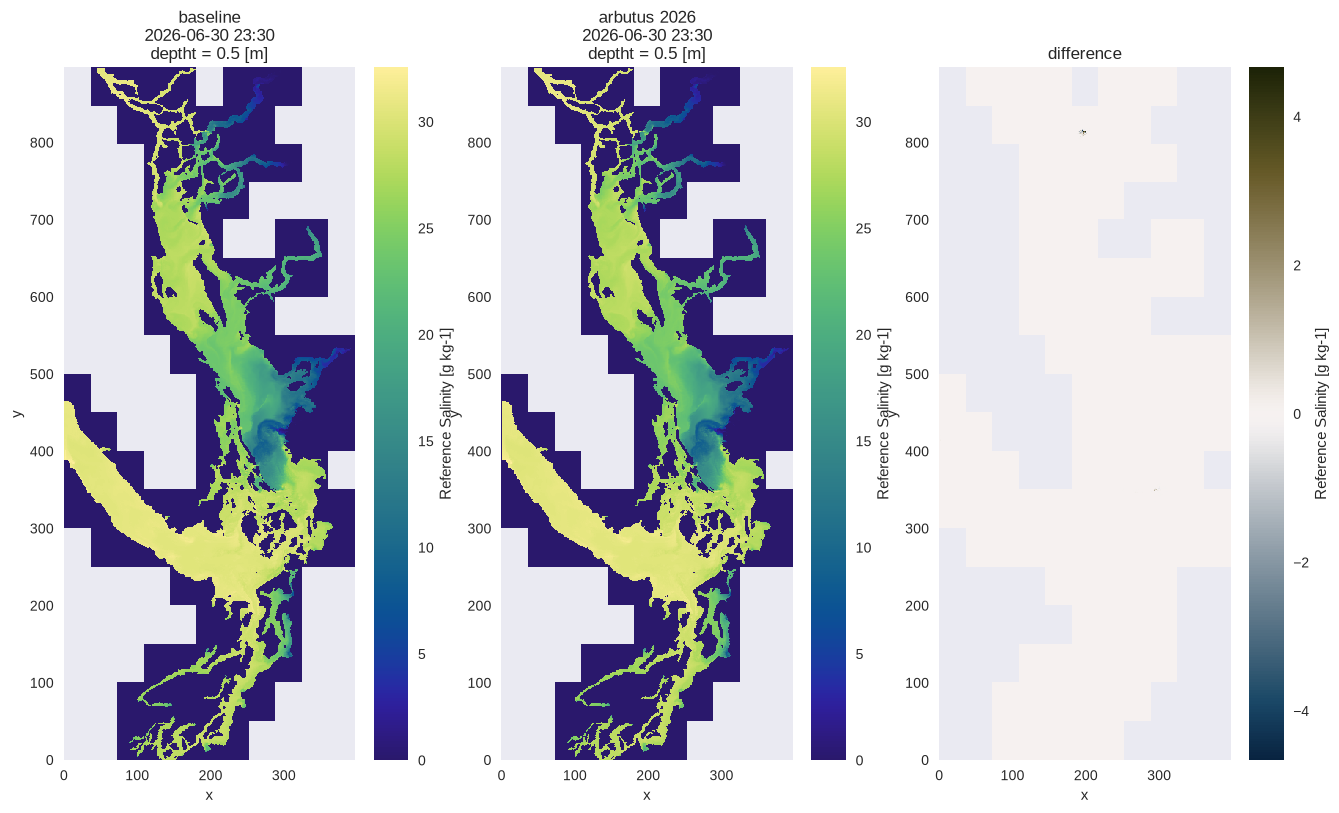

In [16]:
_, (axref, axcomp, axdiff) = plt.subplots(1, 3, figsize=(16, 9))
timestamp = arrow.get(pandas.to_datetime(baseline_ds.time_counter)[-1]).format("YYYY-MM-DD HH:mm")

baseline_sal = baseline_ds.vosaline.isel(time_counter=-1, deptht=0)
baseline_sal.plot(ax=axref, cmap=cmocean.cm.haline)
axref.set_title(f"baseline\n{timestamp}\n{axref.get_title().split(",")[0]}")

new_arbutus_sal = new_arbutus_ds.vosaline.isel(time_counter=-1, deptht=0)
new_arbutus_sal.plot(ax=axcomp, cmap=cmocean.cm.haline)
axcomp.set_title(f"arbutus 2026\n{timestamp}\n{axcomp.get_title().split(",")[0]}")

(baseline_sal - new_arbutus_sal).plot(ax=axdiff, cmap=cmocean.cm.diff)
axdiff.set_title("difference");

In [12]:
xarray.ufuncs.abs((baseline_sal - new_arbutus_sal)).max().item()

4.664995193481445

Nearly identical surface salinity fields indicate that the `nowcast-blue` (physics-only) run from the 2026 `arbutus.cloud`
is equivalent to the one from the pre-2026 `arbutus.cloud`.